In [2]:
!pip install tensorflow

In [3]:

import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
import matplotlib.pyplot as plt



In [4]:
#trabajar con el dataset
data = pd.read_csv('titanic.csv')

In [5]:
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:
# preprocesar los datos
#seleccionar las caracteristicas relevantes
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
data = data[features + ['Survived']].dropna()

In [7]:
data

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived
0,3,male,22.0,1,0,7.2500,S,0
1,1,female,38.0,1,0,71.2833,C,1
2,3,female,26.0,0,0,7.9250,S,1
3,1,female,35.0,1,0,53.1000,S,1
4,3,male,35.0,0,0,8.0500,S,0
...,...,...,...,...,...,...,...,...
885,3,female,39.0,0,5,29.1250,Q,0
886,2,male,27.0,0,0,13.0000,S,0
887,1,female,19.0,0,0,30.0000,S,1
889,1,male,26.0,0,0,30.0000,C,1


In [8]:
# codificar variables categoricas
label_encoders = {}
for column in ['Sex', 'Embarked']: 
    le = LabelEncoder() 
    data[column] = le.fit_transform(data[column])
    label_encoders[column] = le

In [9]:
data.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived
0,3,1,22.0,1,0,7.2500,2,0
1,1,0,38.0,1,0,71.2833,0,1
2,3,0,26.0,0,0,7.9250,2,1
3,1,0,35.0,1,0,53.1000,2,1
4,3,1,35.0,0,0,8.0500,2,0


In [10]:
#Separar caracteristicas (x) y etiquetas (y)
X = data.drop('Survived', axis=1).values
y = data['Survived'].values

In [11]:
X

array([[ 3.    ,  1.    , 22.    , ...,  0.    ,  7.25  ,  2.    ],
       [ 1.    ,  0.    , 38.    , ...,  0.    , 71.2833,  0.    ],
       [ 3.    ,  0.    , 26.    , ...,  0.    ,  7.925 ,  2.    ],
       ...,
       [ 1.    ,  0.    , 19.    , ...,  0.    , 30.    ,  2.    ],
       [ 1.    ,  1.    , 26.    , ...,  0.    , 30.    ,  0.    ],
       [ 3.    ,  1.    , 32.    , ...,  0.    ,  7.75  ,  1.    ]],
      shape=(712, 7))

In [12]:
y

array([0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0,
       0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0,
       1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0,
       1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0,
       1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1,
       1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0,

In [13]:
# El escalado debe aprenderse únicamente del conjunto de entrenamiento.
# Se realiza después de separar los datos para evitar fuga de información.


In [14]:
# Dividir datos: entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Estandarizar con estadísticas SOLO de entrenamiento
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [23]:
#Definir modelo de la red neuronal
model = keras.Sequential([
    layers.Dense(16, activation='relu', input_shape=(7,)),
    layers.Dense(8, activation='relu'),
    layers.Dense(1,activation='sigmoid')])

In [24]:
#Compilar modelo
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [25]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                      │ (None, 16)                  │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 273 (1.07 KB)

 Trainable params: 273 (1.07 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
#Entrenar modelo
history = model.fit(X_train, y_train, epochs=200,
                    batch_size=32, validation_split=0.2, verbose=1)

Epoch 1/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 117ms/step - accuracy: 0.6066 - loss: 0.6521 - val_accuracy: 0.6667 - val_loss: 0.6883
Epoch 2/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6374 - loss: 0.6225 - val_accuracy: 0.6667 - val_loss: 0.6670
Epoch 3/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6769 - loss: 0.6004 - val_accuracy: 0.7018 - val_loss: 0.6511
Epoch 4/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7121 - loss: 0.5816 - val_accuracy: 0.7281 - val_loss: 0.6388
Epoch 5/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7451 - loss: 0.5652 - val_accuracy: 0.7193 - val_loss: 0.6289
Epoch 6/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7604 - loss: 0.5504 - val_accuracy: 0.7193 - val_loss: 0.6199
Epoch 7/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7692 - loss: 0.5367 - val_accuracy: 0.7456 - val_loss: 0.6122
Epoch 8/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7780 - loss: 0.5245 - val_accuracy: 0

In [27]:
#Entrenar modelo ahora con 800
history = model.fit(X_train, y_train, epochs=800,
                    batch_size=32, validation_split=0.2, verbose=1)

Epoch 1/800
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.8659 - loss: 0.3075 - val_accuracy: 0.7807 - val_loss: 0.6242
Epoch 2/800
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8659 - loss: 0.3073 - val_accuracy: 0.7807 - val_loss: 0.6253
Epoch 3/800
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8659 - loss: 0.3070 - val_accuracy: 0.7807 - val_loss: 0.6263
Epoch 4/800
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8659 - loss: 0.3069 - val_accuracy: 0.7807 - val_loss: 0.6257
Epoch 5/800
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8659 - loss: 0.3066 - val_accuracy: 0.7807 - val_loss: 0.6275
Epoch 6/800
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8681 - loss: 0.3063 - val_accuracy: 0.7807 - val_loss: 0.6278
Epoch 7/800
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8681 - loss: 0.3061 - val_accuracy: 0.7807 - val_loss: 0.6285
Epoch 8/800
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8681 - loss: 0.3059 - val_accuracy: 0.

In [28]:
# Evaluar la red neuronal con los datos de prueba
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f'Pérdida (loss) en prueba: {test_loss:.4f}')
print(f'Accuracy en prueba: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)')

Pérdida (loss) en prueba: 0.7032
Accuracy en prueba: 0.7972 (79.72%)


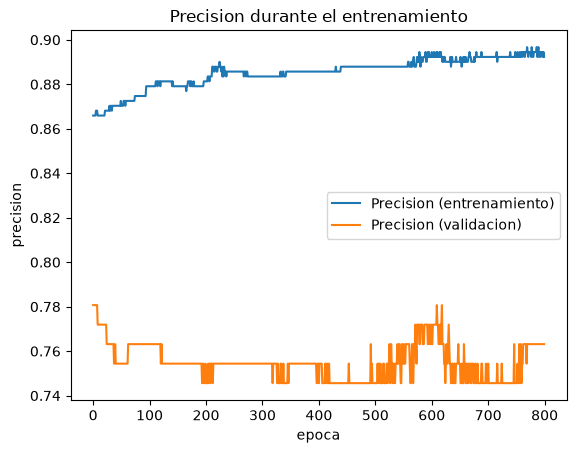

In [33]:
plt.plot(history.history['accuracy'], label='Precision (entrenamiento)')
plt.plot(history.history['val_accuracy'], label='Precision (validacion)')
plt.title('Precision durante el entrenamiento')
plt.xlabel('epoca')
plt.ylabel('precision')
plt.legend()
plt.show()

## Evaluación de clasificación: Accuracy, Recall, F1-Score y matriz de confusión

Las siguientes métricas se calculan sobre **X_test**, es decir, el conjunto reservado para prueba. La clase **1** indica que el pasajero sobrevivió y la clase **0** que no sobrevivió.

La red produce una probabilidad de supervivencia entre 0 y 1. Para obtener una predicción de clase se usa el umbral **0.5**.

In [34]:
# 1. Obtener probabilidades y convertirlas en clases (0 = no, 1 = sí)
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print('Primeras 10 probabilidades:', np.round(y_prob[:10], 3))
print('Primeras 10 predicciones:', y_pred[:10])
print('Primeros 10 valores reales:', y_test[:10])

Primeras 10 probabilidades: [0.975 0.003 0.907 0.001 0.125 0.108 0.    0.989 0.035 1.   ]
Primeras 10 predicciones: [1 0 1 0 0 0 0 1 0 1]
Primeros 10 valores reales: [1 0 1 1 0 0 0 1 0 1]


### Cálculo de las métricas

- **VP:** verdadero positivo (predijo supervivencia y sí sobrevivió).
- **VN:** verdadero negativo (predijo que no sobrevivió y no sobrevivió).
- **FP:** falso positivo (predijo supervivencia, pero no sobrevivió).
- **FN:** falso negativo (predijo que no sobrevivió, pero sí sobrevivió).

**Accuracy** = (VP + VN) / (VP + VN + FP + FN)

**Precision** = VP / (VP + FP)

**Recall** = VP / (VP + FN)

**F1-Score** = 2 × (Precision × Recall) / (Precision + Recall).

Si una división carece de denominador, `zero_division=0` evita un error y asigna 0 a la métrica no definida.

In [35]:
# 2. Calcular métricas con scikit-learn
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print('=== MÉTRICAS DE CLASIFICACIÓN (CONJUNTO DE PRUEBA) ===')
print(f'Accuracy : {accuracy:.4f} ({accuracy*100:.2f}%)')
print(f'Precision: {precision:.4f} ({precision*100:.2f}%)')
print(f'Recall   : {recall:.4f} ({recall*100:.2f}%)')
print(f'F1-Score : {f1:.4f} ({f1*100:.2f}%)')

print('\nReporte por clase:')
print(classification_report(
    y_test, y_pred, labels=[0, 1],
    target_names=['No sobrevivió', 'Sobrevivió'], zero_division=0
))

=== MÉTRICAS DE CLASIFICACIÓN (CONJUNTO DE PRUEBA) ===
Accuracy : 0.7972 (79.72%)
Precision: 0.7544 (75.44%)
Recall   : 0.7414 (74.14%)
F1-Score : 0.7478 (74.78%)

Reporte por clase:
               precision    recall  f1-score   support

No sobrevivió       0.83      0.84      0.83        85
   Sobrevivió       0.75      0.74      0.75        58

     accuracy                           0.80       143
    macro avg       0.79      0.79      0.79       143
 weighted avg       0.80      0.80      0.80       143



### Matriz de confusión

Se comparan los valores reales con las predicciones del modelo. Con el orden `[0, 1]`, la matriz tiene esta disposición:

| | Predijo 0 (no sobrevivió) | Predijo 1 (sobrevivió) |
|---|---:|---:|
| **Real 0** | VN | FP |
| **Real 1** | FN | VP |

La diagonal principal corresponde a los aciertos; las otras dos celdas representan errores.

Matriz de confusión (filas = reales; columnas = predicciones):
[[71 14]
 [15 43]]
Verdaderos negativos (VN): 71
Falsos positivos (FP): 14
Falsos negativos (FN): 15
Verdaderos positivos (VP): 43


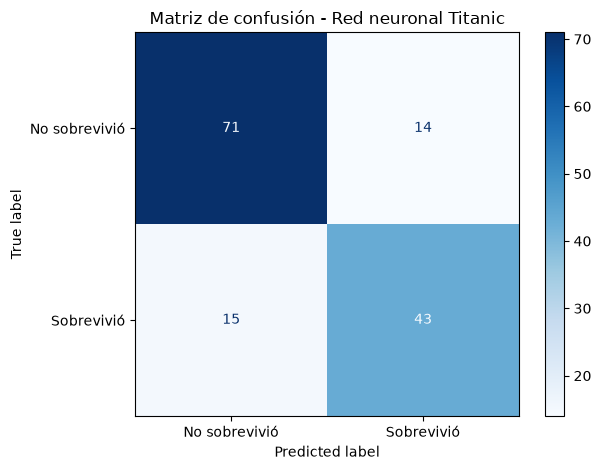

In [36]:
# 3. Construir y visualizar la matriz de confusión
matriz = confusion_matrix(y_test, y_pred, labels=[0, 1])
print('Matriz de confusión (filas = reales; columnas = predicciones):')
print(matriz)

VN, FP, FN, VP = matriz.ravel()
print(f'Verdaderos negativos (VN): {VN}')
print(f'Falsos positivos (FP): {FP}')
print(f'Falsos negativos (FN): {FN}')
print(f'Verdaderos positivos (VP): {VP}')

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=['No sobrevivió', 'Sobrevivió']
)
disp.plot(cmap='Blues', values_format='d')
plt.title('Matriz de confusión - Red neuronal Titanic')
plt.tight_layout()
plt.show()

### Comprobación manual de las fórmulas e interpretación

Se usan los cuatro valores extraídos de la matriz de confusión para verificar que las métricas obtenidas con `sklearn` coinciden con su definición matemática.

In [37]:
# 4. Verificar los resultados usando las fórmulas matemáticas
accuracy_manual = (VP + VN) / (VP + VN + FP + FN)
precision_manual = VP / (VP + FP) if (VP + FP) else 0
recall_manual = VP / (VP + FN) if (VP + FN) else 0
f1_manual = (2 * precision_manual * recall_manual /
             (precision_manual + recall_manual)
             if (precision_manual + recall_manual) else 0)

print(f'Accuracy (manual): {accuracy_manual:.4f}')
print(f'Precision (manual): {precision_manual:.4f}')
print(f'Recall (manual): {recall_manual:.4f}')
print(f'F1-Score (manual): {f1_manual:.4f}')

assert np.isclose(accuracy, accuracy_manual)
assert np.isclose(precision, precision_manual)
assert np.isclose(recall, recall_manual)
assert np.isclose(f1, f1_manual)
print('\nComprobación correcta: las fórmulas coinciden con scikit-learn.')

Accuracy (manual): 0.7972
Precision (manual): 0.7544
Recall (manual): 0.7414
F1-Score (manual): 0.7478

Comprobación correcta: las fórmulas coinciden con scikit-learn.


### Conclusión de la práctica

El **Accuracy** indica la proporción total de pasajeros clasificados correctamente. El **Recall** muestra cuántos de los pasajeros que sí sobrevivieron fueron identificados como supervivientes. El **F1-Score** evalúa el equilibrio entre Precision y Recall. La **matriz de confusión** permite observar en qué tipo de casos se equivoca la red.

**Nota metodológica:** se corrigió el orden de separación y escalado para que `StandardScaler` no aprenda información de los datos de prueba. Las cifras reales dependen del entrenamiento del modelo y se obtienen al ejecutar las celdas. Las 200 y 800 épocas originales se conservaron.